In [111]:
import pandas as pd
import numpy as np
import json
from config import *
import os
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import mixedlm

# Main Model

In [162]:
rows=[]
outpath='outfolder/'
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)
        
        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append({
                        "name": name,
                        "representation": filename[:-5],
                        "model": model,
                        "metric": metric,
                        "value": value
                    })

# Build DataFrame
df = pd.DataFrame(rows)

df

,name,representation,model,metric,value
0,BD135193,GC_count,RF,roc_auc,0.620370
1,BD135193,GC_count,RF,pr_auc,0.752758
2,BD135193,GC_count,RF,precision,0.615385
3,BD135193,GC_count,RF,recall,1.000000
4,BD135193,GC_count,RF,fscore,0.761905
...,...,...,...,...,...
6745,XM_371822,atomic_number,DT,roc_auc,0.669540
6746,XM_371822,atomic_number,DT,pr_auc,0.519485
6747,XM_371822,atomic_number,DT,precision,0.587302
6748,XM_371822,atomic_number,DT,recall,0.637931


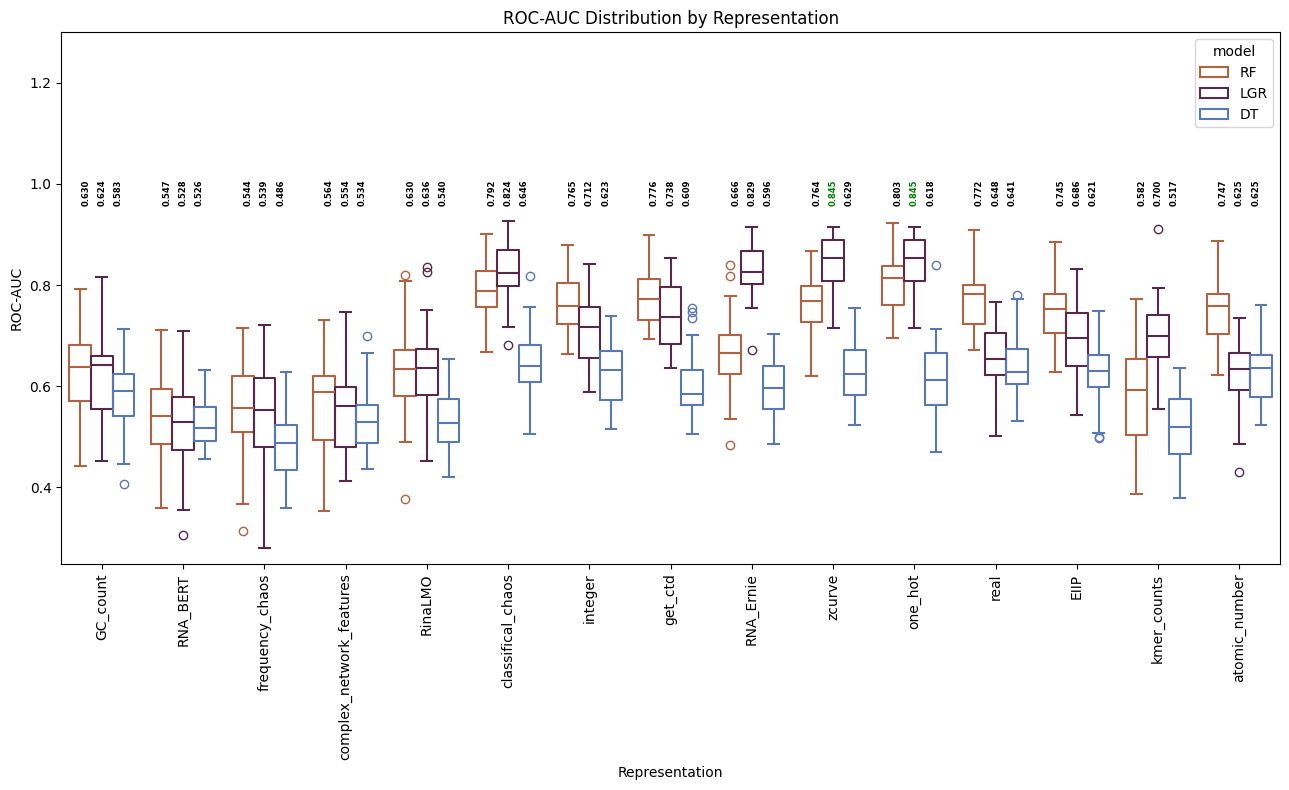

In [163]:
df_auc = df[df["metric"] == "roc_auc"]

plt.figure(figsize=(13,8))
sns.boxplot(x="representation", y="value", data=df_auc, hue='model', palette='managua',fill=False)
plt.ylabel("ROC-AUC")
plt.xlabel("Representation")
plt.ylim(top=1.3)
plt.title("ROC-AUC Distribution by Representation")
plt.xticks(rotation=90)
box_positions={}
avg_vals = df_auc.groupby(["representation", "model"])["value"].mean().reset_index()
y_max = df_auc["value"].max()
# Get positions of the boxes
models = df_auc["model"].unique()
for i, rep in enumerate(df_auc["representation"].unique()):
    for j, model in enumerate(models):
        box_positions[(rep, model)] = i + (j - (len(models)-1)/2) * 0.2  # adjust for hue width
        
max_val = round(avg_vals["value"].max(), 3)
# Annotate means at the top (same height for all)
for _, row in avg_vals.iterrows():
    pos = box_positions[(row["representation"], row["model"])]
    color = "green" if round(row["value"],3) == max_val else "black"
    plt.text(pos, y_max + 0.03, f"{row['value']:.3f}",
             ha='center', va='bottom', fontsize=6, fontweight="bold", color=color, rotation=90)
plt.tight_layout()
plt.savefig('ROC-AUC.png',dpi=300)


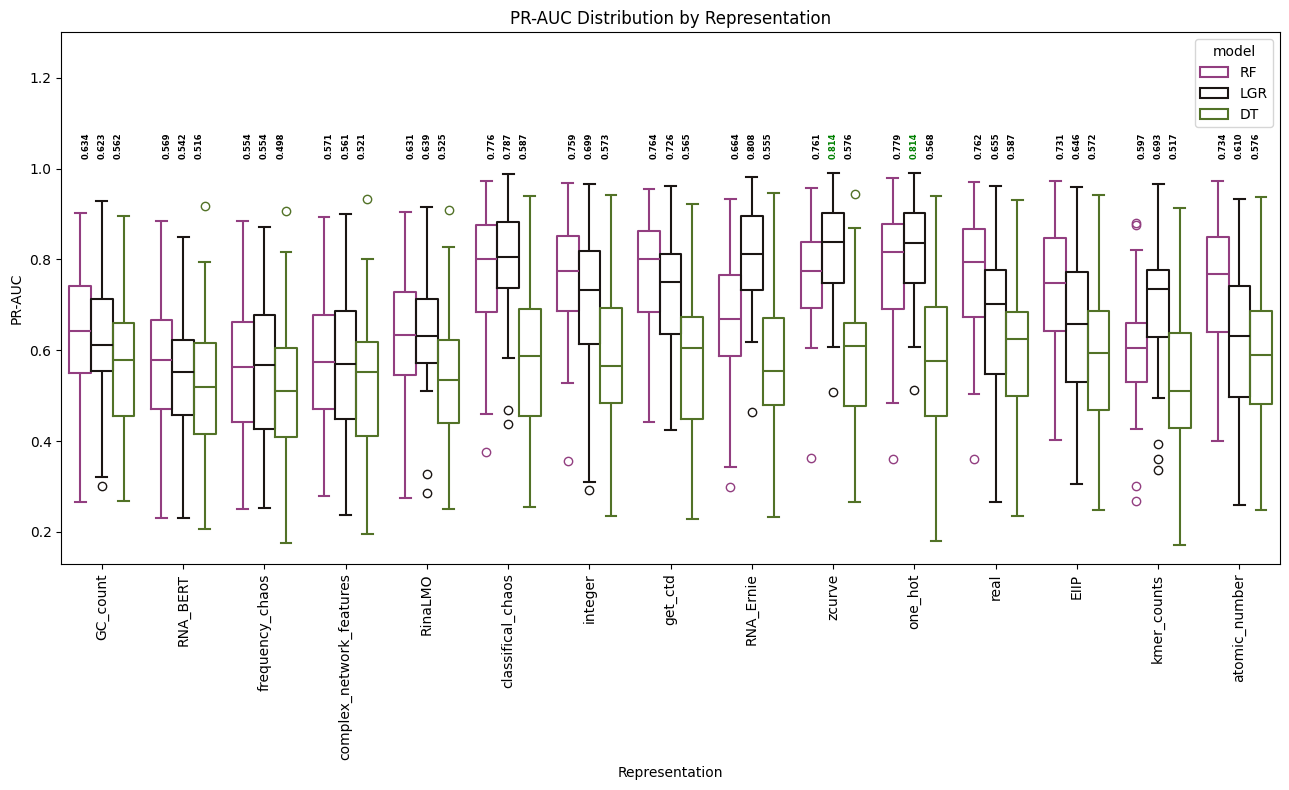

In [164]:
df_auc = df[df["metric"] == "pr_auc"]

plt.figure(figsize=(13,8))
sns.boxplot(x="representation", y="value", data=df_auc, hue='model', palette='vanimo',fill=False)
plt.ylabel("PR-AUC")
plt.xlabel("Representation")
plt.title("PR-AUC Distribution by Representation")
plt.xticks(rotation=90)
box_positions={}
avg_vals = df_auc.groupby(["representation", "model"])["value"].mean().reset_index()
y_max = df_auc["value"].max()
# Get positions of the boxes
models = df_auc["model"].unique()
for i, rep in enumerate(df_auc["representation"].unique()):
    for j, model in enumerate(models):
        box_positions[(rep, model)] = i + (j - (len(models)-1)/2) * 0.2  # adjust for hue width
        
max_val = round(avg_vals["value"].max(), 3)
# Annotate means at the top (same height for all)
for _, row in avg_vals.iterrows():
    pos = box_positions[(row["representation"], row["model"])]
    color = "green" if round(row["value"],3) == max_val else "black"
    plt.text(pos, y_max + 0.03, f"{row['value']:.3f}",
             ha='center', va='bottom', fontsize=6, fontweight="bold", color=color, rotation=90)

plt.tight_layout()
plt.ylim(top=1.3)
plt.savefig('PR-AUC.png',dpi=300)


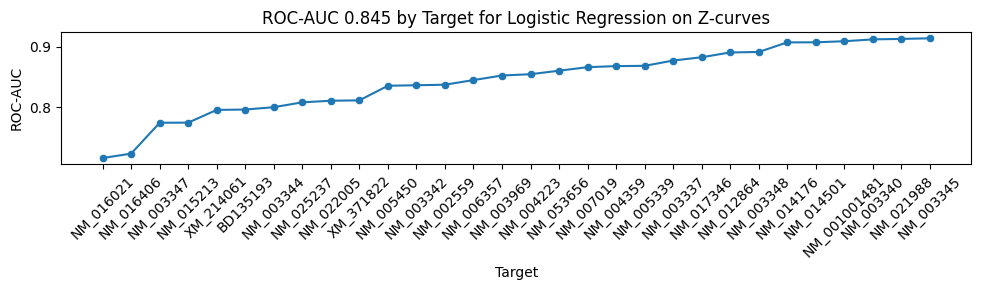

In [166]:
filtered_df = df[(df['model'] == 'LGR') & 
                 (df['representation'] == 'zcurve') & 
                 (df['metric'] == 'roc_auc')]

# Sort by value ascending
filtered_df = filtered_df.sort_values(by='value')
mean_roc=np.round(np.mean(filtered_df['value']),3)
# Scatter line plot
plt.figure(figsize=(10,3))
sns.scatterplot(data=filtered_df, x='name', y='value')
sns.lineplot(data=filtered_df, x='name', y='value', sort=False)

plt.xticks(rotation=45)
plt.xlabel('Target')
plt.ylabel('ROC-AUC')
plt.title(f'ROC-AUC {mean_roc} by Target for Logistic Regression on Z-curves')
plt.tight_layout()
plt.savefig('LGR_ZCURVE_ROC.png',dpi=300)

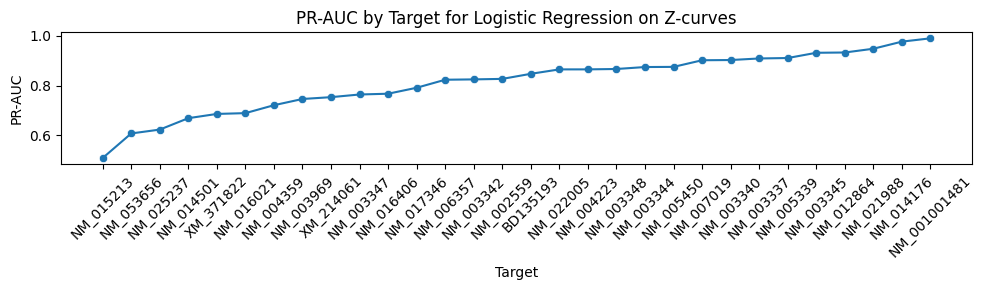

In [127]:
filtered_df = df[(df['model'] == 'LGR') & 
                 (df['representation'] == 'zcurve') & 
                 (df['metric'] == 'pr_auc')]

# Sort by value ascending
filtered_df = filtered_df.sort_values(by='value')

# Scatter line plot
plt.figure(figsize=(10,3))
sns.scatterplot(data=filtered_df, x='name', y='value')
sns.lineplot(data=filtered_df, x='name', y='value', sort=False)

plt.xticks(rotation=45)
plt.xlabel('Target')
plt.ylabel('PR-AUC')
plt.title('PR-AUC by Target for Logistic Regression on Z-curves')
plt.tight_layout()
plt.savefig('LGR_ZCURVE_PR.png',dpi=300)

# Sliding Window

In [128]:
rows=[]
outpath='sliding_outfolder/'
for filename in ['zcurve_'+str(i)+'.json' for i in range(0,21)]:
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)
        
        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append({
                        "name": name,
                        "window": filename[:-5],
                        "model": model,
                        "metric": metric,
                        "value": value
                    })

# Build DataFrame
df = pd.DataFrame(rows)

df

,name,window,model,metric,value
0,BD135193,zcurve_0,RF,roc_auc,0.814815
1,BD135193,zcurve_0,RF,pr_auc,0.842395
2,BD135193,zcurve_0,RF,precision,0.785714
3,BD135193,zcurve_0,RF,recall,0.825000
4,BD135193,zcurve_0,RF,fscore,0.804878
...,...,...,...,...,...
9445,XM_371822,zcurve_20,DT,roc_auc,0.528835
9446,XM_371822,zcurve_20,DT,pr_auc,0.413430
9447,XM_371822,zcurve_20,DT,precision,0.407895
9448,XM_371822,zcurve_20,DT,recall,0.534483


/tmp/ipykernel_348132/335203527.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="window", y="value", data=df_auc, palette='managua',fill=False)


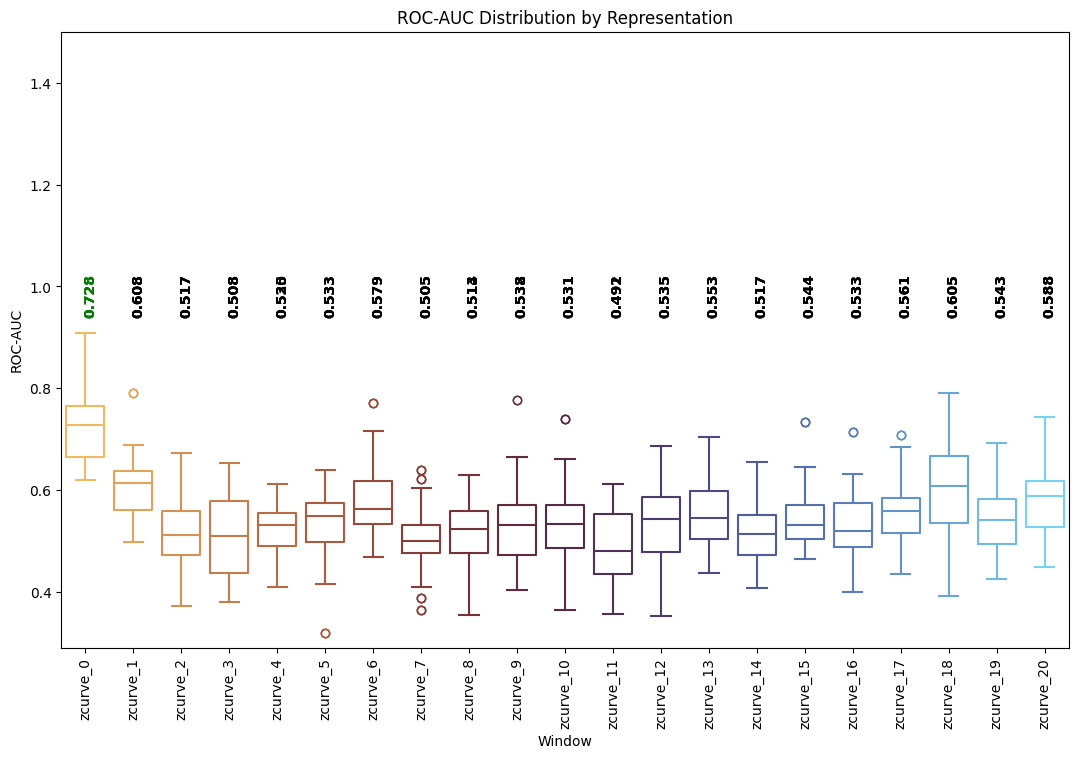

In [129]:
df_auc = df[df["metric"] == "roc_auc"]

plt.figure(figsize=(13,8))
sns.boxplot(x="window", y="value", data=df_auc, palette='managua',fill=False)
plt.ylabel("ROC-AUC")
plt.xlabel("Window")
plt.ylim(top=1.5)
plt.title("ROC-AUC Distribution by Representation")
plt.xticks(rotation=90)
box_positions={}
avg_vals = df_auc.groupby(["window", "model"])["value"].mean().reset_index()
y_max = df_auc["value"].max()
# Get positions of the boxes

for i, rep in enumerate(df_auc["window"].unique()):
        box_positions[(rep)] = i + ((1)/2) * 0.2  # adjust for hue width
        
max_val = round(avg_vals["value"].max(), 3)
# Annotate means at the top (same height for all)
for _, row in avg_vals.iterrows():
    pos = box_positions[(row["window"])]
    color = "green" if round(row["value"],3) == max_val else "black"
    plt.text(pos, y_max + 0.03, f"{row['value']:.3f}",
             ha='center', va='bottom', fontsize=10, fontweight="bold", color=color, rotation=90)

plt.savefig('ROC-AUC_Sliding.png',dpi=300)


# Correlation

In [91]:
data=pd.read_csv(datapath)
huesken_index=data.index[data['sources']=='Huesken'].tolist()
data=data.loc[huesken_index]
data['shuffled_B']=np.random.permutation(data['B'])
data.head(5)

,Unnamed: 0,A,B,efficacy,Label,siRNA_seq,mRNA_seq,sources,shuffled_B
0,0,A1,BD135193,0.462,0.0,CTAATATGTTAATTGATTTAT,ATAAAATTGAAAGGAATTGTATAAATCAATTAACATATTAGCTGAGTTG,Huesken,NM_001001481
1,1,A2,BD135193,0.384,0.0,AATATGTTAATTGATTTATAC,AGATAAAATTGAAAGGAATTGTATAAATCAATTAACATATTAGCTG...,Huesken,NM_015213
2,2,A3,BD135193,0.514,0.0,GATTTATACAATTCCTTTCAA,CTGCTTATTTTTAGATAAAATTGAAAGGAATTGTATAAATCAATTA...,Huesken,NM_003347
3,3,A4,BD135193,0.364,0.0,CAATTCCTTTCAATTTTATCT,ATTTTGGTCTGCTTATTTTTAGATAAAATTGAAAGGAATTGTATAA...,Huesken,NM_004223
4,4,A5,BD135193,0.522,0.0,CAGACCAAAATTAAATAAGAA,AAATGGAATCTTATGTAACTTTCTTATTTAATTTTGGTCTGCTTAT...,Huesken,NM_006357


### Chi- Square

H0: 2 categorical variables are independent

In [92]:
from scipy.stats import chi2_contingency
tab=pd.crosstab(data['B'],data['Label'])
_,p,_,_=chi2_contingency(tab)
print('p-value: ',p)

p-value:  5.816607929690996e-42


In [93]:
from scipy.stats import chi2_contingency
tab=pd.crosstab(data['shuffled_B'],data['Label'])
_,p,_,_=chi2_contingency(tab)
print('p-value: ',p)

p-value:  0.21359307263997393


### ANOVA

H0: All group means equal

In [94]:
groups = [group["efficacy"].values for name, group in data.groupby("B")]
f_stat, p_val = stats.f_oneway(*groups)
print("F-statistic:", f_stat)
print("p-value:", p_val)

F-statistic: 17.109517620484493
p-value: 9.588064056179317e-78


In [95]:
groups = [group["efficacy"].values for name, group in data.groupby("shuffled_B")]
f_stat, p_val = stats.f_oneway(*groups)
print("F-statistic:", f_stat)
print("p-value:", p_val)

F-statistic: 1.211007526687406
p-value: 0.2025620259004909


### ICC

ICC 0 -> no correlation between observations within group

In [96]:
model=mixedlm('efficacy ~ 1', data, groups=data['B'])
result=model.fit()

print('ICC: '+ str(result.cov_re.iloc[0,0]/(result.cov_re.iloc[0,0]+result.scale)))

ICC: 0.16481148262267914


/ceph/users/ahm22224/miniconda3/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


In [97]:
model=mixedlm('efficacy ~ 1', data, groups=data['shuffled_B'])
result=model.fit()

print('ICC: '+ str(result.cov_re.iloc[0,0]/(result.cov_re.iloc[0,0]+result.scale)))

ICC: 0.002256888870713274


/ceph/users/ahm22224/miniconda3/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


/tmp/ipykernel_348132/1698059567.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="B", y="efficacy", data=data, palette="Set2")


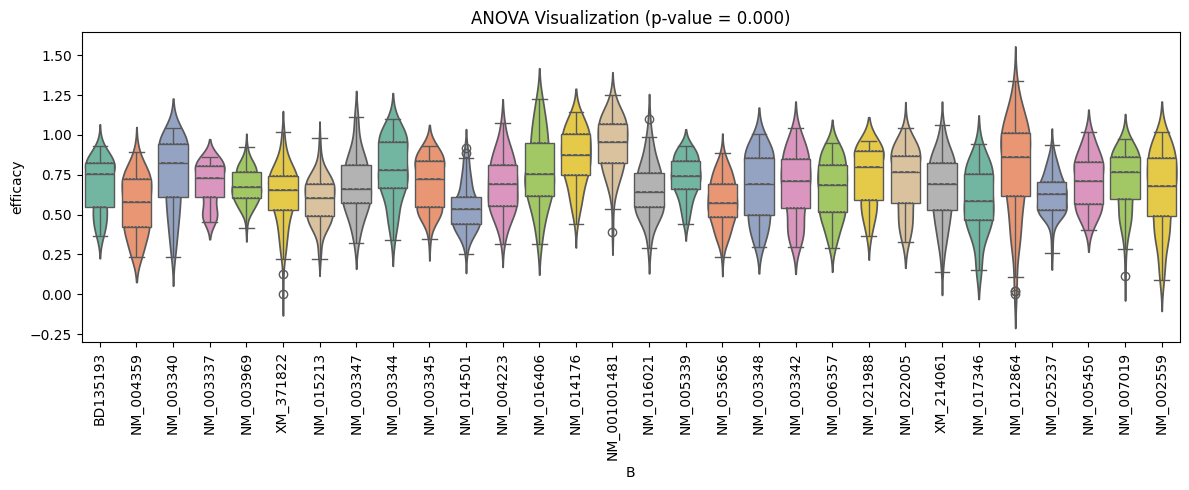

In [44]:
plt.figure(figsize=(12,5))
sns.boxplot(x="B", y="efficacy", data=data, palette="Set2")
sns.violinplot(x="B", y="efficacy", data=data, palette="Set2", inner="quartile", hue='B')
plt.title(f"ANOVA Visualization (p-value = {p_val:.3f})")
plt.xlabel("B")
plt.xticks(rotation=90)
plt.ylabel("efficacy")
plt.tight_layout()
plt.savefig('Data Distribution.png',dpi=300)

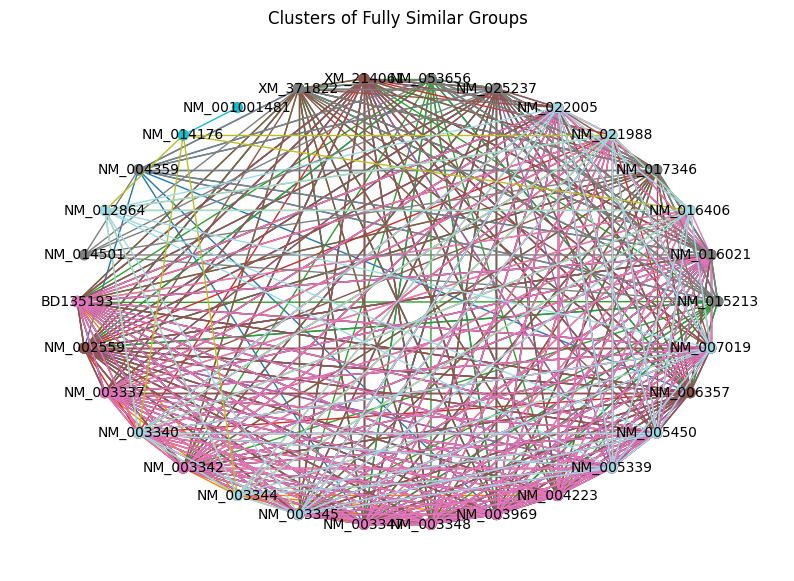

In [66]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import networkx as nx
np.random.seed(42)

groups=np.unique(data['B'])
tukey = pairwise_tukeyhsd(endog=data["efficacy"], groups=data["B"], alpha=0.05)

similar_pairs = [(row[0], row[1]) for row in tukey._results_table.data[1:] if row[-1] == False]
# Build graph
G = nx.Graph()
G.add_edges_from(similar_pairs)
G.add_nodes_from(groups)

# Find **all maximal cliques** (fully connected groups of any size)
cliques = list(nx.find_cliques(G))
#print("Maximal fully connected clusters:", cliques)

# Plot network
plt.figure(figsize=(10,7))
pos = nx.shell_layout(G)
colors = plt.cm.tab20(np.linspace(0,1,len(cliques)))

for i, clique in enumerate(cliques):
    # Draw nodes of the clique
    nx.draw_networkx_nodes(G, pos, nodelist=clique, node_color=[colors[i]]*len(clique), node_size=50)
    # Draw edges inside the clique
    edges = [(clique[m], clique[n]) for m in range(len(clique)) for n in range(m+1, len(clique))]
    nx.draw_networkx_edges(G, pos, edgelist=edges, width=1, edge_color=[colors[i]]*len(edges))

# Draw remaining edges not in any clique (if any)
edges_in_cliques = set([tuple(sorted(e)) for clique in cliques for e in [(clique[m], clique[n]) for m in range(len(clique)) for n in range(m+1, len(clique))]])
remaining_edges = [e for e in G.edges if tuple(sorted(e)) not in edges_in_cliques]
nx.draw_networkx_edges(G, pos, edgelist=remaining_edges, style='dashed', edge_color='black', width=1)

nx.draw_networkx_labels(G, pos, font_size=10)
plt.title("Clusters of Fully Similar Groups")
plt.axis('off')
plt.savefig('clusters.png',dpi=300)

/tmp/ipykernel_348132/3455095709.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="B", y="efficacy", data=cluster_data, ax=axes[i], palette="Set2")
/tmp/ipykernel_348132/3455095709.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45)
/tmp/ipykernel_348132/3455095709.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="B", y="efficacy", data=cluster_data, ax=axes[i], palette="Set2")
/tmp/ipykernel_348132/3455095709.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a Fi

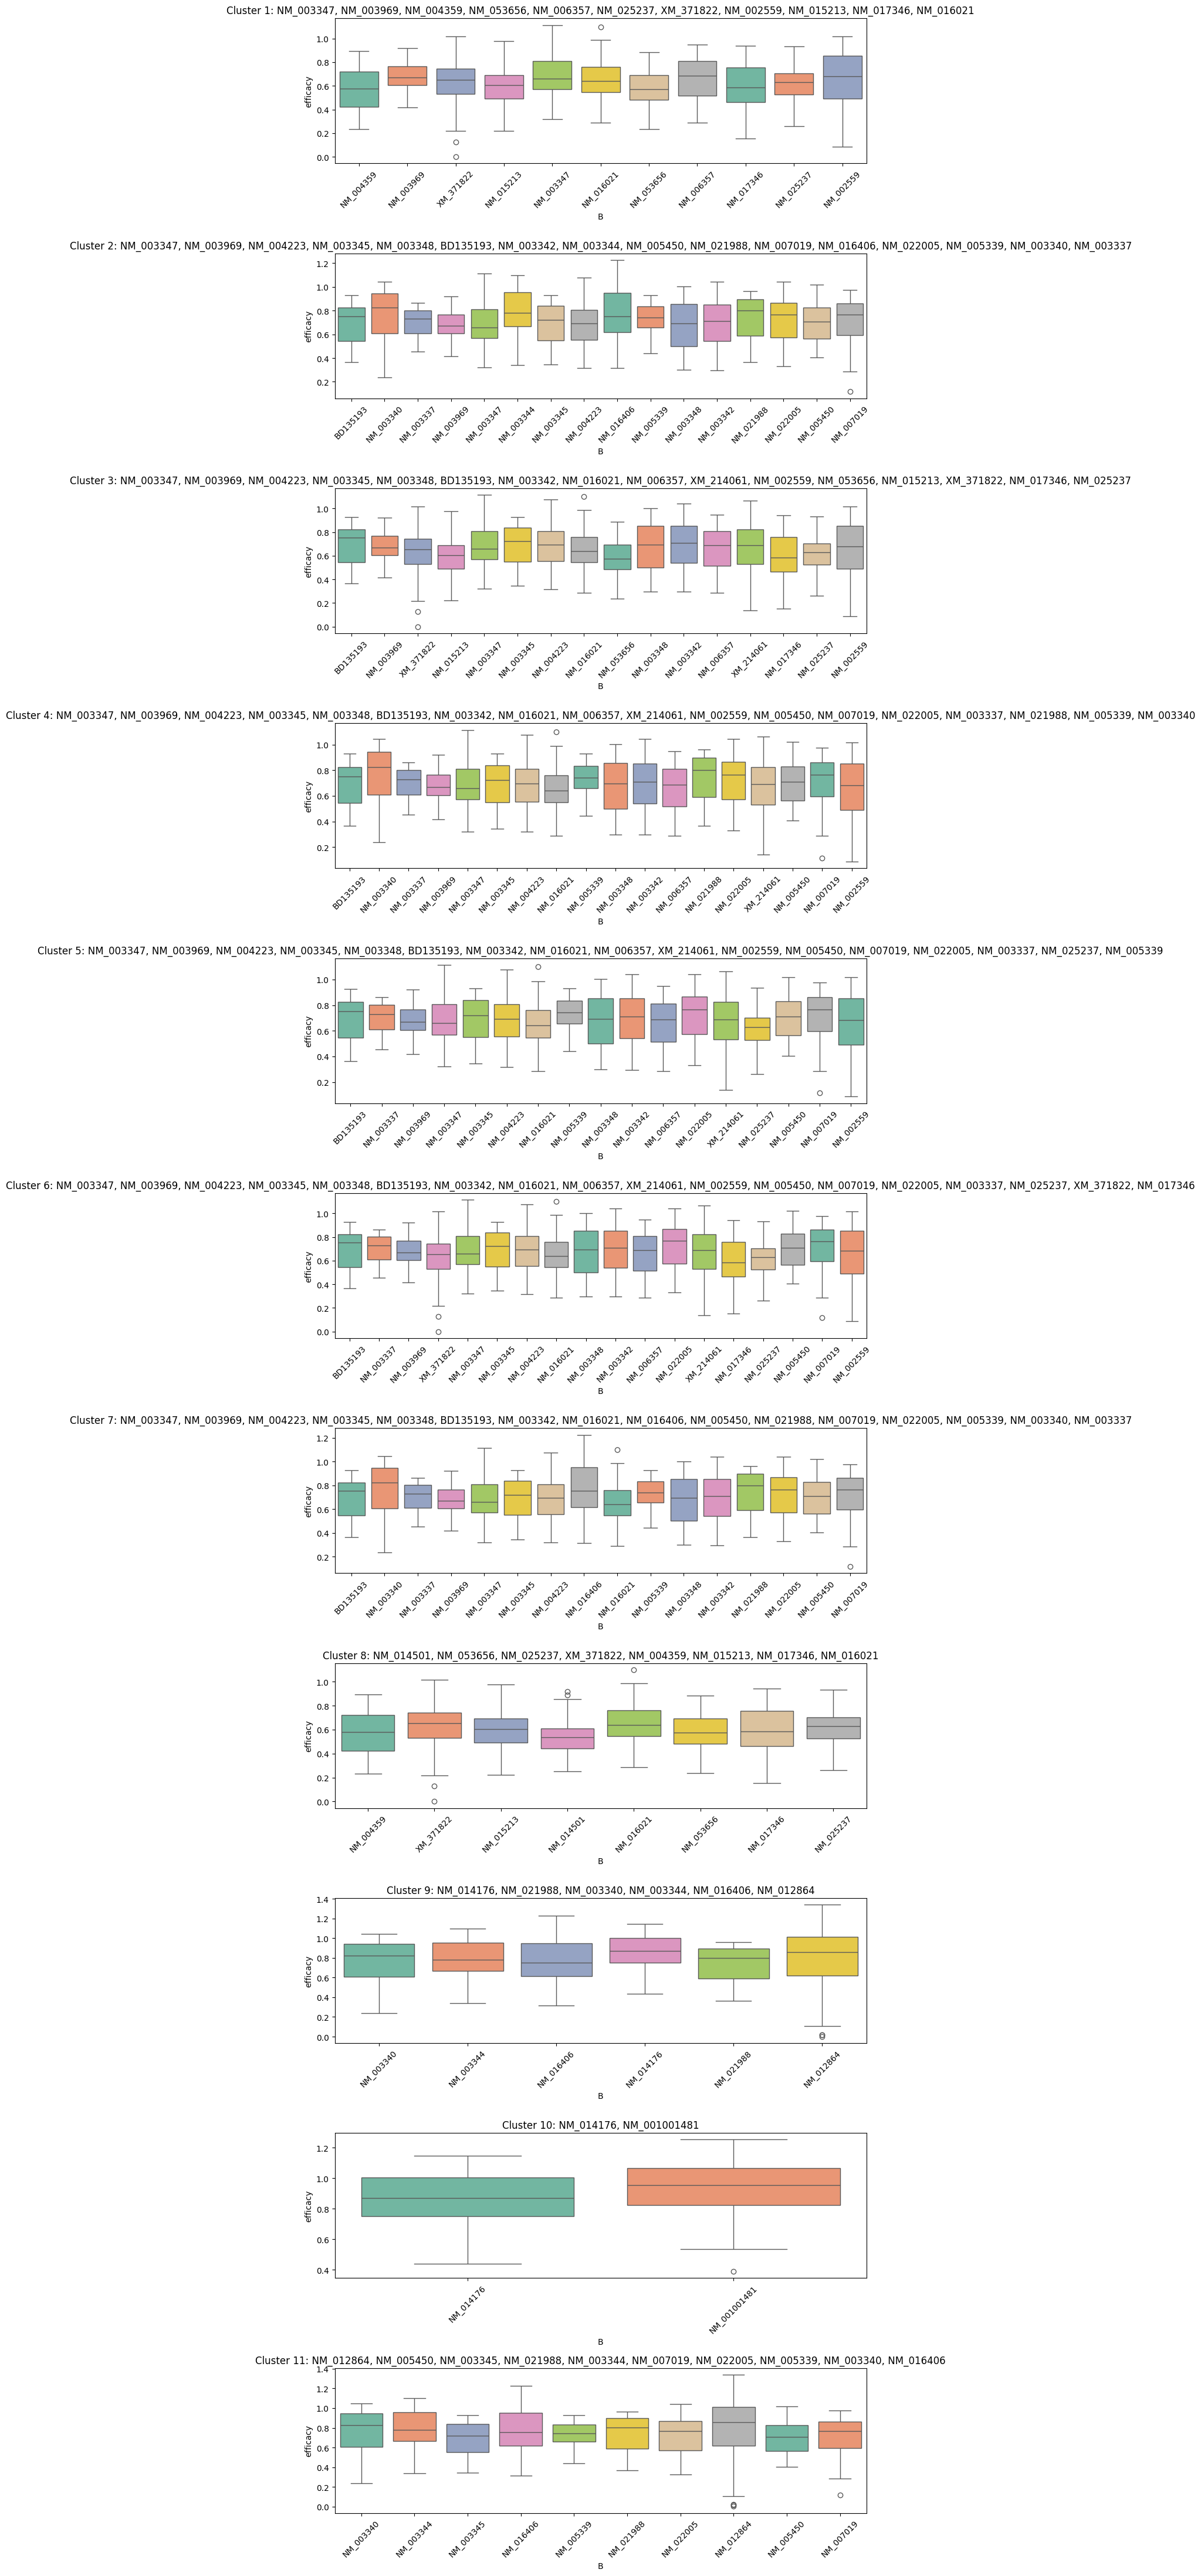

In [75]:
G = nx.Graph()
G.add_edges_from(similar_pairs)
G.add_nodes_from(groups)
cliques = list(nx.find_cliques(G))  # maximal fully connected clusters

# Plot each cluster in a separate subplot
n = len(cliques)
fig, axes = plt.subplots(n, 1, figsize=(10, 4*n), sharex=False)

if n == 1:
    axes = [axes]  # make iterable if only one cluster

for i, clique in enumerate(cliques):
    cluster_data = data[data["B"].isin(clique)]
    sns.boxplot(x="B", y="efficacy", data=cluster_data, ax=axes[i], palette="Set2")
    #sns.stripplot(x="B", y="efficacy", data=cluster_data, ax=axes[i], color="black", size=5, jitter=True)
    axes[i].set_title(f"Cluster {i+1}: {', '.join(clique)}")
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45)

plt.tight_layout()
plt.savefig('clusters_Subplot.png',dpi=300)

# GSS Bias

/tmp/ipykernel_348132/3711658570.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(test_results[test_size].keys(), rotation=90,size=8)
/tmp/ipykernel_348132/3711658570.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(test_results[test_size].keys(), rotation=90,size=8)
/tmp/ipykernel_348132/3711658570.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(test_results[test_size].keys(), rotation=90,size=8)
/tmp/ipykernel_348132/3711658570.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(test_results[test_size].keys(), rotation=90,size=8)


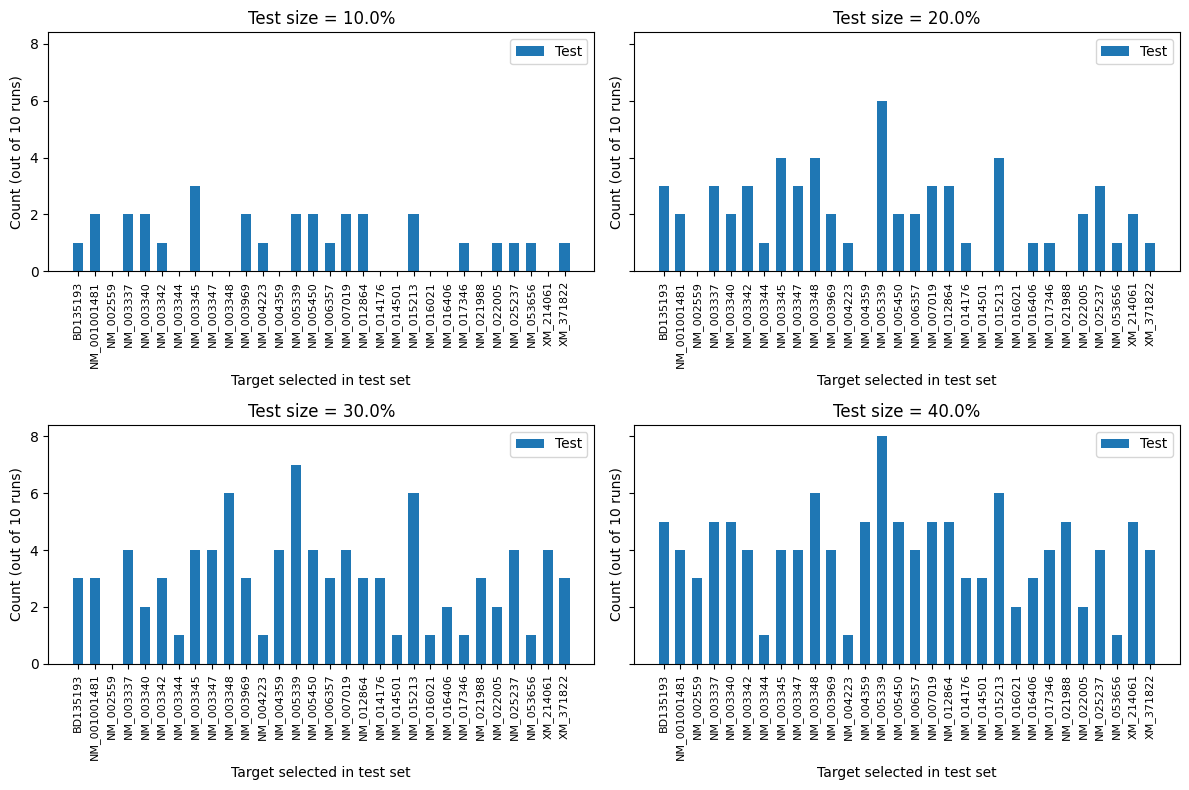

In [153]:
from sklearn.model_selection import GroupShuffleSplit

data=pd.read_csv(datapath)
huesken_index=data.index[data['sources']=='Huesken'].tolist()
data=data.loc[huesken_index]

X = data['A']
y = data['Label']
groups = data['B']

# Test sizes to explore
test_sizes = [0.1, 0.2, 0.3, 0.4]

# Dictionary of dictionaries to store test counts for each test size
test_results = {}

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
axes = axes.flatten()

for i, test_size in enumerate(test_sizes):
    gss = GroupShuffleSplit(n_splits=10, test_size=test_size, random_state=42)

    # Counter for how many times each group is selected into test
    test_counts = {name: 0 for name in np.unique(groups)}

    # Run the splits
    for train_idx, test_idx in gss.split(X, y, groups):
        test_groups = np.unique(groups[test_idx])
        #print(test_groups)
        for g in test_groups:
            test_counts[g] += 1

    test_results[test_size] = test_counts

    axes[i].bar(test_results[test_size].keys(),test_results[test_size].values(), width=0.6, label='Test')

    axes[i].set_xlabel('Target selected in test set')
    axes[i].set_ylabel('Count (out of 10 runs)')
    axes[i].set_title(f'Test size = {test_size*100}%')
    axes[i].set_xticklabels(test_results[test_size].keys(), rotation=90,size=8)
    #axes[i].set_xticklabels([f"g{l}" for l in labels])
    axes[i].legend()

plt.tight_layout()
plt.savefig('GSS_bias.png')
plt.show()




# Fixed Size test

In [155]:
data=pd.read_csv(datapath)
huesken_index=data.index[data['sources']=='Huesken'].tolist()
data=data.loc[huesken_index]
freq_df = data['B'].value_counts().reset_index()
freq_df.columns = ['Target', 'Frequency']
freq_df

,Target,Frequency
0,NM_012864,150
1,XM_371822,145
2,XM_214061,144
3,NM_015213,126
4,NM_002559,90
5,NM_014501,79
6,NM_005339,79
7,NM_003348,79
8,NM_006357,79
9,NM_003342,79


In [169]:
rows=[]
outpath='more_tests/'
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)
        
        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append({
                        "name": name,
                        "representation": filename[:-5],
                        "model": model,
                        "metric": metric,
                        "value": value
                    })

# Build DataFrame
df = pd.DataFrame(rows)

df

,name,representation,model,metric,value
0,Other,zcurve_holdout,RF,roc_auc,0.679699
1,Other,zcurve_holdout,RF,pr_auc,0.687121
2,Other,zcurve_holdout,RF,precision,0.620536
3,Other,zcurve_holdout,RF,recall,0.691542
4,Other,zcurve_holdout,RF,fscore,0.654118
...,...,...,...,...,...
460,XM_371822,zcurve_fixed,DT,roc_auc,0.560345
461,XM_371822,zcurve_fixed,DT,pr_auc,0.433505
462,XM_371822,zcurve_fixed,DT,precision,0.462687
463,XM_371822,zcurve_fixed,DT,recall,0.534483


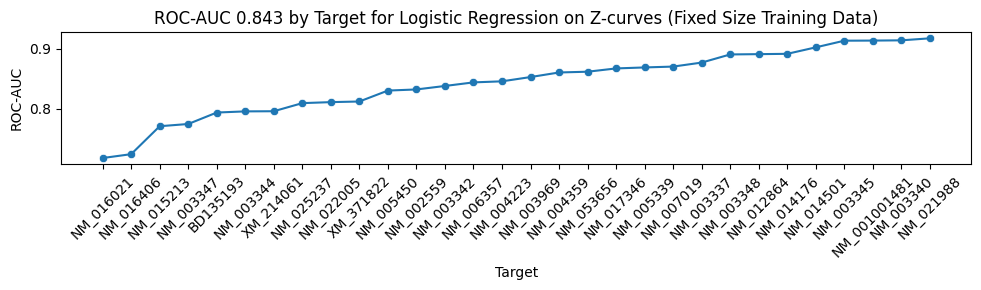

In [171]:
filtered_df = df[(df['model'] == 'LGR') & 
                 (df['representation'] == 'zcurve_fixed') & 
                 (df['metric'] == 'roc_auc')]

# Sort by value ascending
filtered_df = filtered_df.sort_values(by='value')
mean_roc=np.round(np.mean(filtered_df['value']),3)
# Scatter line plot
plt.figure(figsize=(10,3))
sns.scatterplot(data=filtered_df, x='name', y='value')
sns.lineplot(data=filtered_df, x='name', y='value', sort=False)

plt.xticks(rotation=45)
plt.xlabel('Target')
plt.ylabel('ROC-AUC')
plt.title(f'ROC-AUC {mean_roc} by Target for Logistic Regression on Z-curves (Fixed Size Training Data)')
plt.tight_layout()
plt.savefig('LGR_ZCURVE_ROC_FIXEDSIZE.png',dpi=300)

# Test on Rest

In [156]:
full_data=pd.read_csv(datapath)
freq_df = full_data['sources'].value_counts().reset_index()
freq_df.columns = ['Source', 'Frequency']
freq_df

,Source,Frequency
0,Huesken,2431
1,Other,385


In [172]:
rows=[]
outpath='more_tests/'
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)
        
        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append({
                        "name": name,
                        "representation": filename[:-5],
                        "model": model,
                        "metric": metric,
                        "value": value
                    })

# Build DataFrame
df = pd.DataFrame(rows)

df

,name,representation,model,metric,value
0,Other,zcurve_holdout,RF,roc_auc,0.679699
1,Other,zcurve_holdout,RF,pr_auc,0.687121
2,Other,zcurve_holdout,RF,precision,0.620536
3,Other,zcurve_holdout,RF,recall,0.691542
4,Other,zcurve_holdout,RF,fscore,0.654118
...,...,...,...,...,...
460,XM_371822,zcurve_fixed,DT,roc_auc,0.560345
461,XM_371822,zcurve_fixed,DT,pr_auc,0.433505
462,XM_371822,zcurve_fixed,DT,precision,0.462687
463,XM_371822,zcurve_fixed,DT,recall,0.534483


In [179]:
filtered_df = df[(df['model'] == 'LGR') & 
                 (df['representation'] == 'zcurve_holdout') & 
                 (df['metric'] == 'roc_auc')]

print(filtered_df)


    name  representation model   metric     value
5  Other  zcurve_holdout   LGR  roc_auc  0.752785
